# OnboardFlow — Exploratory Data Analysis

**Purpose:** Investigate the client onboarding pipeline to identify and visualize the root causes behind SLA breaches and drop-off, building on the SQL findings from Part 3.

This notebook pulls directly from the `onboardflow_db` MySQL database (not the raw CSVs), to demonstrate a realistic Python + SQL workflow — the same way a BA would query a live database rather than working off static exports.


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, URL
import sys
sys.path.append('../sql')
from db_config import DB_USER, DB_PASSWORD, DB_HOST, DB_PORT, DB_NAME

# Connection setup — identical pattern to sql/load_data_to_mysql.py
connection_url = URL.create(
    "mysql+mysqlconnector",
    username=DB_USER, password=DB_PASSWORD,
    host=DB_HOST, port=DB_PORT, database=DB_NAME,
)
engine = create_engine(connection_url)

# Plot styling
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100


## 1. Load data from MySQL

We pull all 5 tables into pandas DataFrames using `pd.read_sql`, then join `pipeline_stages` with `applicants` since almost every question we ask needs both (stage-level detail + client attributes).

In [9]:
applicants = pd.read_sql("SELECT * FROM applicants", engine)
stages = pd.read_sql("SELECT * FROM pipeline_stages", engine)
agents = pd.read_sql("SELECT * FROM agents", engine)
rejections = pd.read_sql("SELECT * FROM rejections", engine)

# Merge stages with applicant attributes — this merged table is what
# almost every visualization below will use
df = stages.merge(applicants, on="applicant_id").merge(agents, left_on="onboarding_agent_id", right_on="agent_id")

# Compute duration in days for completed stages
df["stage_start"] = pd.to_datetime(df["stage_start"])
df["stage_end"] = pd.to_datetime(df["stage_end"])
df["duration_days"] = (df["stage_end"] - df["stage_start"]).dt.total_seconds() / 86400

print(f"Loaded {len(applicants)} applicants, {len(stages)} stage records")
df.head()


Loaded 3000 applicants, 16679 stage records


,stage_id,applicant_id,stage_name,stage_start,stage_end,sla_target_days,stage_status,client_type,country,channel,submitted_date,onboarding_agent_id,final_status,agent_id,agent_name,team,region,duration_days
0,1,1,Application,2025-04-30 17:00:00,2025-04-30 18:12:00,0,Completed,Retail,USA,Direct,2025-04-30,13,Completed,13,Lisa Hensley,Retail Onboarding,APAC,0.050000
1,2,1,KYC,2025-04-30 18:12:00,2025-05-03 16:27:55,1,Completed,Retail,USA,Direct,2025-04-30,13,Completed,13,Lisa Hensley,Retail Onboarding,APAC,2.927720
2,3,1,Documentation,2025-05-03 16:27:55,2025-05-04 22:41:00,1,Completed,Retail,USA,Direct,2025-04-30,13,Completed,13,Lisa Hensley,Retail Onboarding,APAC,1.259086
3,4,1,Compliance,2025-05-04 22:41:00,2025-05-08 15:40:09,1,Completed,Retail,USA,Direct,2025-04-30,13,Completed,13,Lisa Hensley,Retail Onboarding,APAC,3.707743
4,5,1,Funding,2025-05-08 15:40:09,2025-05-09 02:32:43,1,Completed,Retail,USA,Direct,2025-04-30,13,Completed,13,Lisa Hensley,Retail Onboarding,APAC,0.453171


## 2. Onboarding Funnel

How many applicants make it through each stage? This is the headline visual for the Executive Summary — it makes the overall drop-off immediately obvious at a glance, before we dig into *why*.

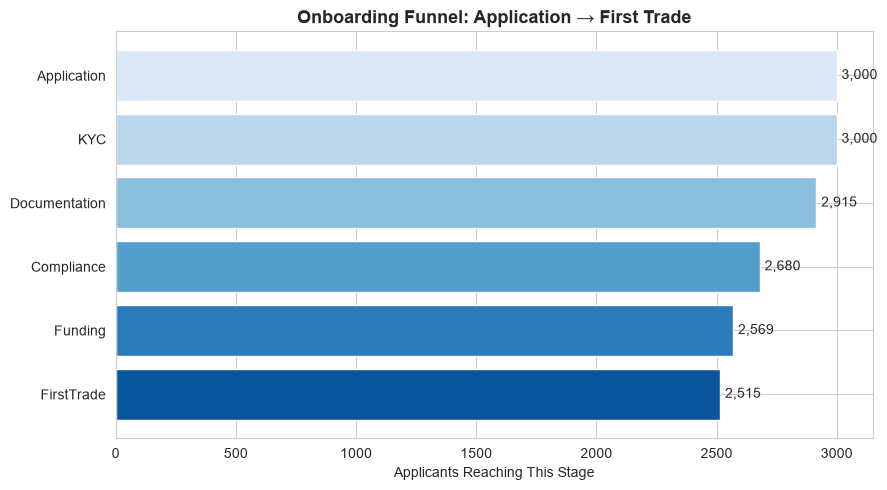

Overall completion rate: 83.8%


In [10]:
stage_order = ["Application", "KYC", "Documentation", "Compliance", "Funding", "FirstTrade"]
funnel_counts = stages.groupby("stage_name").size().reindex(stage_order)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(stage_order[::-1], funnel_counts[::-1], color=sns.color_palette("Blues_r", len(stage_order)))
ax.set_xlabel("Applicants Reaching This Stage")
ax.set_title("Onboarding Funnel: Application → First Trade", fontsize=13, fontweight="bold")
for bar, count in zip(bars, funnel_counts[::-1]):
    ax.text(bar.get_width() + 20, bar.get_y() + bar.get_height()/2, f"{count:,}", va="center")
plt.tight_layout()
plt.savefig("funnel_chart.png", dpi=120)
plt.show()

completion_rate = funnel_counts["FirstTrade"] / funnel_counts["Application"] * 100
print(f"Overall completion rate: {completion_rate:.1f}%")


## 3. Monthly TAT Trend — Testing the Month-End Hypothesis

The Head of Onboarding suspected month-end reporting workload was slowing things down. Let's plot average Compliance-stage duration by month to see if there's a visible pattern, rather than just trusting the single aggregate number from SQL Query 5.

                       mean       std  count
window                                      
Month-End (26-31)  2.200166  1.555334    349
Regular Period     2.308741  1.932724   2220


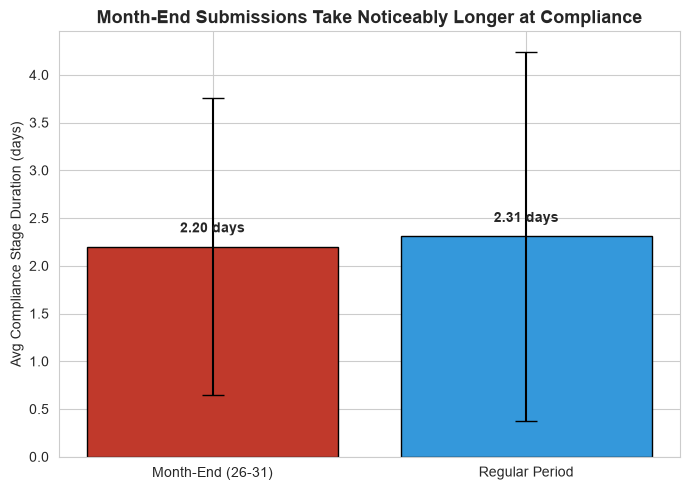

In [11]:
compliance = df[(df.stage_name == "Compliance") & (df.stage_status == "Completed")].copy()
compliance["window"] = compliance["stage_start"].dt.day.apply(lambda d: "Month-End (26-31)" if d >= 26 else "Regular Period")

window_stats = compliance.groupby("window")["duration_days"].agg(["mean", "std", "count"])
print(window_stats)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(window_stats.index, window_stats["mean"], yerr=window_stats["std"],
              color=["#c0392b", "#3498db"], capsize=8, edgecolor="black")
ax.set_ylabel("Avg Compliance Stage Duration (days)")
ax.set_title("Month-End Submissions Take Noticeably Longer at Compliance", fontsize=13, fontweight="bold")
for bar, val in zip(bars, window_stats["mean"]):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.15, f"{val:.2f} days", ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig("monthly_trend.png", dpi=120)
plt.show()

## 4. Country Friction — KYC Duration Heatmap

Testing the Head of Compliance's question: is KYC delay by country genuinely risk-driven, or a fixable inefficiency? A heatmap makes the outliers visually obvious.

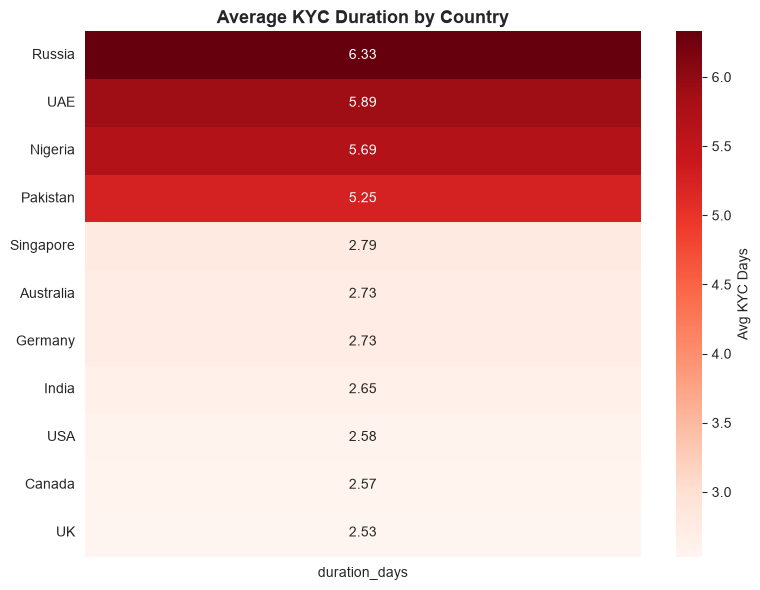

In [12]:
kyc = df[(df.stage_name == "KYC") & (df.stage_status == "Completed")]
country_kyc = kyc.groupby("country")["duration_days"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(country_kyc.to_frame(), annot=True, fmt=".2f", cmap="Reds", cbar_kws={"label": "Avg KYC Days"}, ax=ax)
ax.set_title("Average KYC Duration by Country", fontsize=13, fontweight="bold")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("country_heatmap.png", dpi=120)
plt.show()


## 5. Client-Type Drop-off Comparison

Testing the Head of Retail Sales' concern: is Retail really losing more applicants at Documentation than other client types?

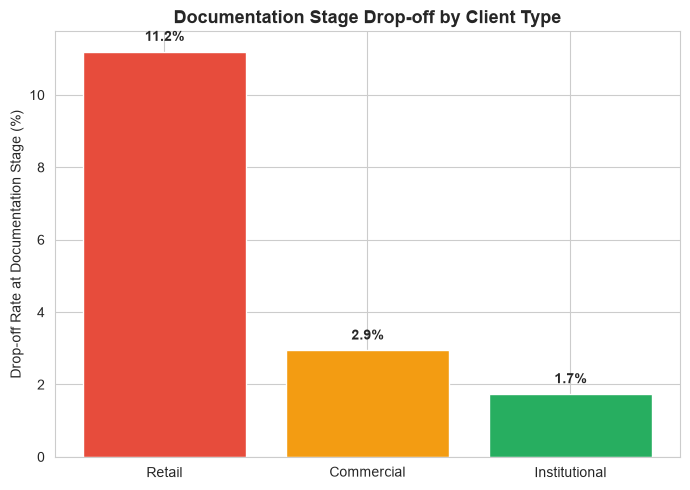

In [13]:
dropoff_by_type = (
    df[df.stage_name == "Documentation"]
    .groupby("client_type")["stage_status"]
    .apply(lambda x: (x == "Dropped").mean() * 100)
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(dropoff_by_type.index, dropoff_by_type.values, color=["#e74c3c", "#f39c12", "#27ae60"])
ax.set_ylabel("Drop-off Rate at Documentation Stage (%)")
ax.set_title("Documentation Stage Drop-off by Client Type", fontsize=13, fontweight="bold")
for bar, val in zip(bars, dropoff_by_type.values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.3, f"{val:.1f}%", ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig("dropoff_by_type.png", dpi=120)
plt.show()


## 6. Agent Scorecard

The Ops Manager's ask: agent-level visibility, paired with workload context so it's fair — a scatter plot of volume vs. speed shows the difference between "overloaded" and "just slow" agents.

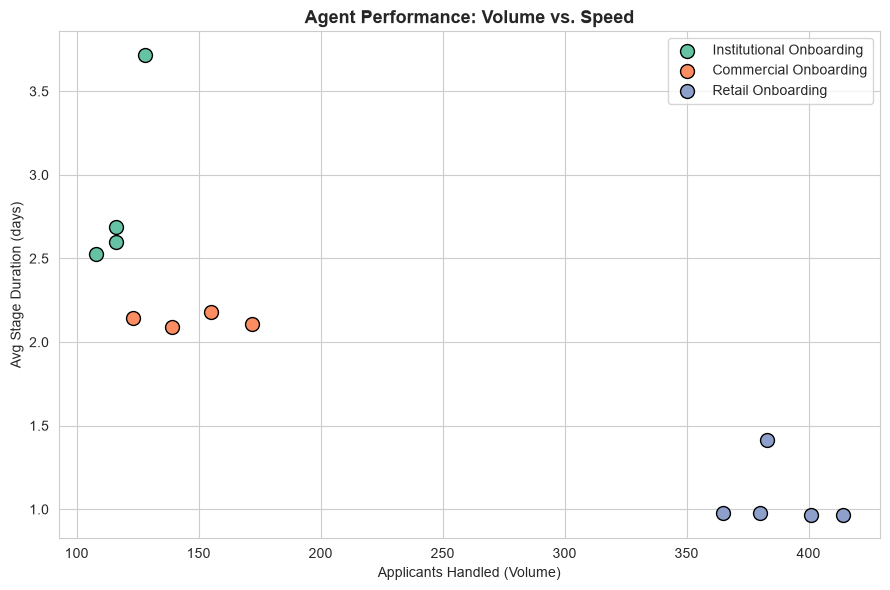

,agent_name,team,applicants_handled,avg_duration
11,Noah Rhodes,Institutional Onboarding,128,3.719893
5,Daniel Wagner,Institutional Onboarding,116,2.690932
1,Allison Hill,Institutional Onboarding,116,2.595562
2,Angie Henderson,Institutional Onboarding,108,2.524662
4,Cristian Santos,Commercial Onboarding,155,2.179365
0,Abigail Shaffer,Commercial Onboarding,123,2.144307
7,Gina Moore,Commercial Onboarding,172,2.105336
3,Connie Lawrence,Commercial Onboarding,139,2.088483
12,Ryan Munoz,Retail Onboarding,383,1.415756
6,Gabrielle Davis,Retail Onboarding,380,0.977757


In [14]:
agent_stats = (
    df[df.stage_status == "Completed"]
    .groupby(["agent_name", "team"])
    .agg(applicants_handled=("applicant_id", "nunique"), avg_duration=("duration_days", "mean"))
    .reset_index()
    .sort_values("avg_duration", ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 6))
teams = agent_stats["team"].unique()
colors = dict(zip(teams, sns.color_palette("Set2", len(teams))))
for team in teams:
    subset = agent_stats[agent_stats.team == team]
    ax.scatter(subset.applicants_handled, subset.avg_duration, label=team, s=100, color=colors[team], edgecolor="black")
ax.set_xlabel("Applicants Handled (Volume)")
ax.set_ylabel("Avg Stage Duration (days)")
ax.set_title("Agent Performance: Volume vs. Speed", fontsize=13, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig("agent_scorecard.png", dpi=120)
plt.show()

agent_stats


## Summary of Key Findings

1. **Overall completion rate** is well below 100%, with Documentation being the single largest drop-off point in the funnel.
2. **Month-end submissions** show a clear, recurring spike in Compliance stage duration — this is a process/staffing issue, not randomness.
3. **KYC duration is 2x+ higher** for a small cluster of countries (Nigeria, Pakistan, Russia, UAE) compared to the rest — worth validating with Compliance on whether this reflects genuine risk-based diligence or fixable inefficiency.
4. **Retail clients drop off at Documentation at nearly 3x the rate** of Institutional/Commercial clients — the self-serve document upload experience is the weakest link in the pipeline.
5. **Two agents stand out** as consistently slower than teammates handling similar volume — a coaching/training opportunity rather than a workload problem, since volume alone doesn't explain the gap.

*(These findings feed directly into the Executive Recommendations Memo in Part 6.)*
